In [ ]:
# prerequisite bash commands

!pip install playwright
!playwright install --with-deps chromium

In [ ]:
# initialize page

playwright = await async_playwright().start()

browser = await playwright.chromium.launch(headless=True)
page = await browser.new_page()

In [ ]:
from IPython.display import Image, display
from playwright.async_api import async_playwright
import getpass
import time

try:
	await page.goto("https://sis-main.hku.hk/sisprod/z_signon.jsp")

	await page.wait_for_url("https://hkuportal.hku.hk/cas/aad")
	print("login")
	email = "u3638801@connect.hku.hk"
	await page.fill("input#email", email)
	await page.click("input.login-btn")

	await page.wait_for_url("https://adfs.connect.hku.hk/adfs/ls/**")
	password = getpass.getpass("%s password:" % email)
	await page.fill("input#passwordInput", password)
	del password
	await page.click("#submitButton")

	await page.wait_for_url("https://login.microsoftonline.com/login.srf")
	await page.click("#idSIButton9")

	await page.wait_for_url("https://login.microsoftonline.com/appverify") 
	await page.click("#idBtn_Back")

	while True:
		if "oauth2" in page.url:
			auth = True
			break
		if "sis" in page.url:
			auth = False
			break
		page.wait_for_timeout(10)

	if auth:
		while (True):
			await page.wait_for_url("https://login.microsoftonline.com/organizations/oauth2/**")
			await page.wait_for_timeout(500)
			print("microsoft authentication")

			img = await page.screenshot(full_page=True)
			display(Image(img))

			if input("can see? ok->Y") == "Y":
				break

		await page.wait_for_url("https://login.microsoftonline.com/common/SAS/ProcessAuth")
		await page.click("#idBtn_Back")

		await page.wait_for_url("https://sis-main.hku.hk/psp/sisprod/EMPLOYEE/SA/h/?tab=Z_SIS_STD_HOMEPAGE")
		print("homepage")

		img = await page.screenshot(full_page=True)
		display(Image(img))
except Exception as err:
	print(err)
	
	img = await page.screenshot(full_page=True)
	display(Image(img))
	
	await browser.close()

	await playwright.close()

CCST


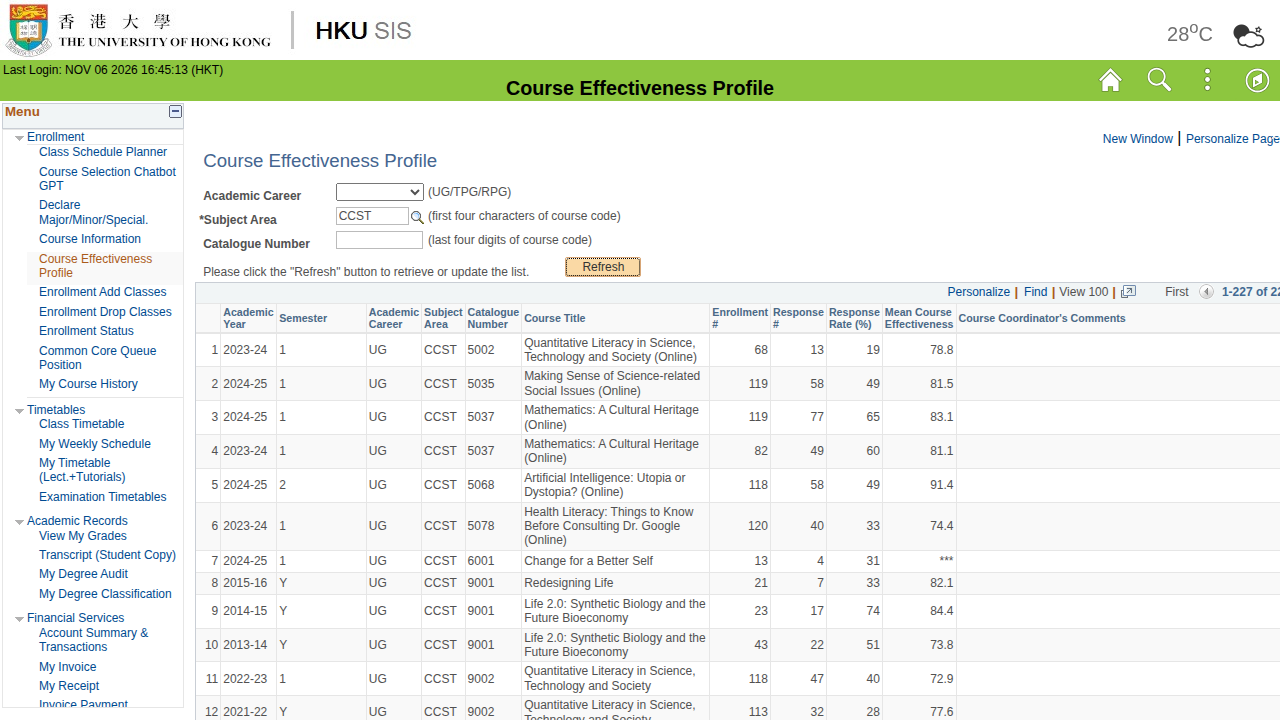

CCHU


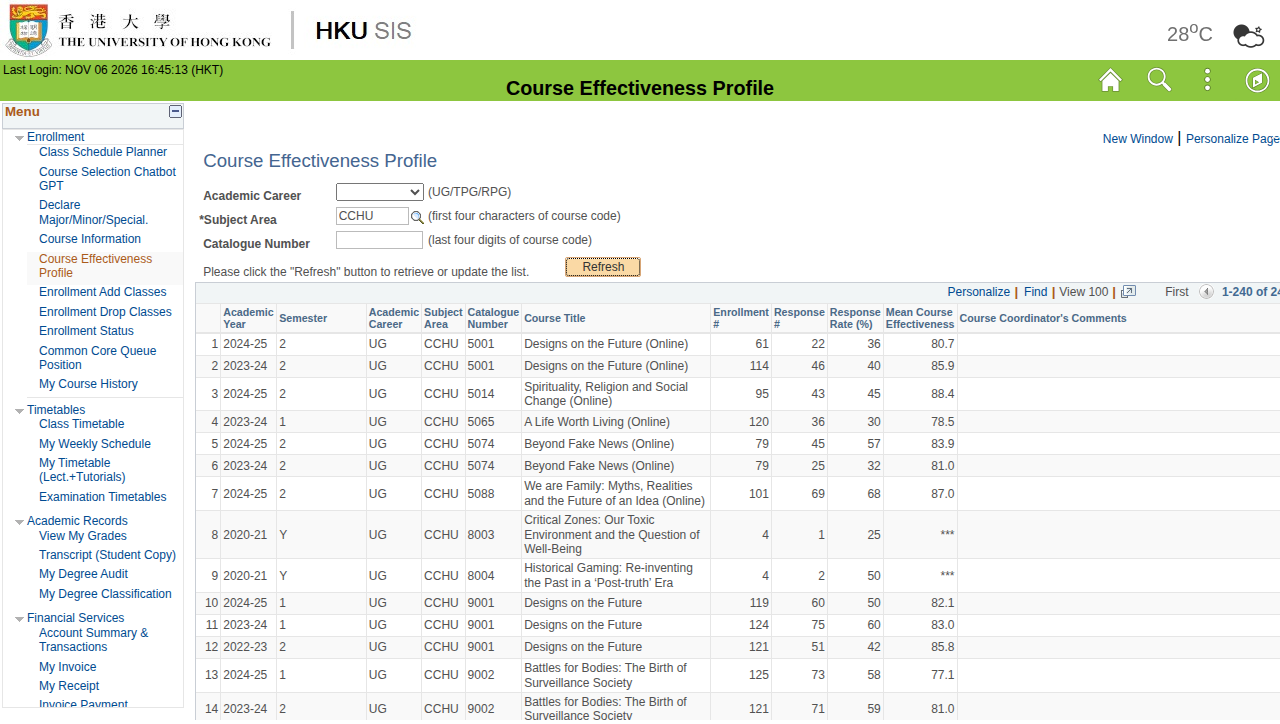

CCGL


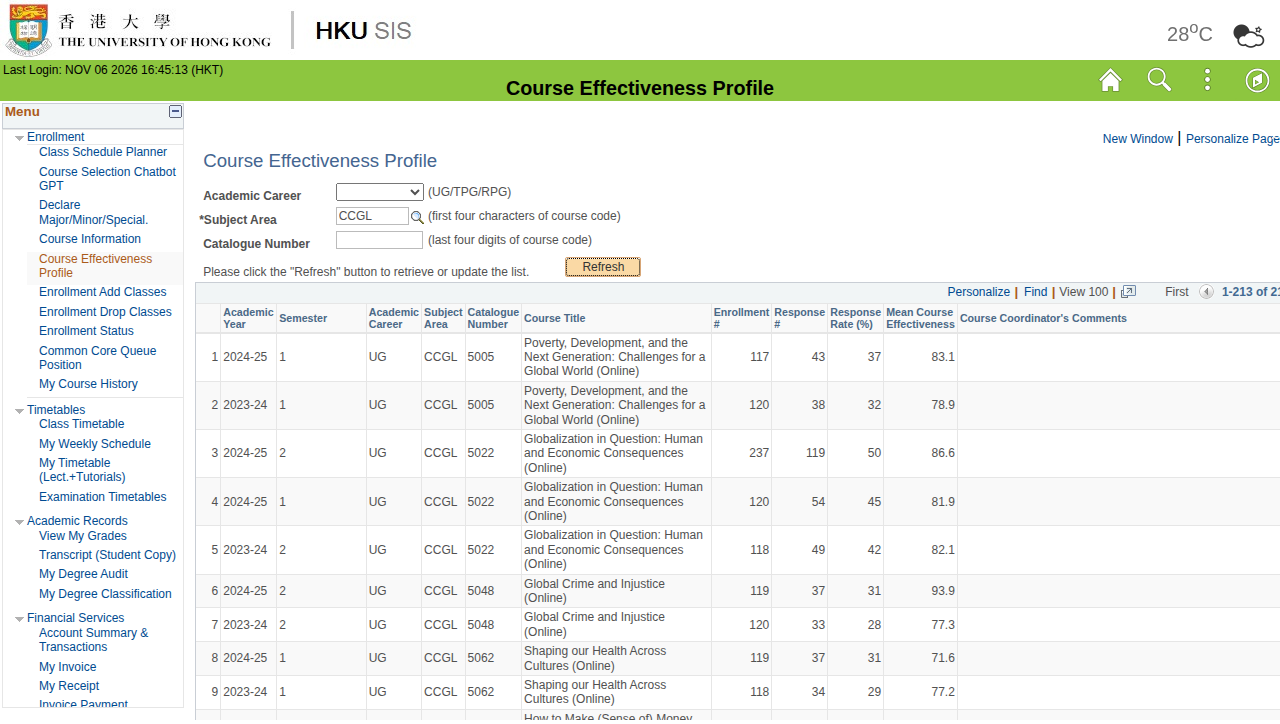

CCCH


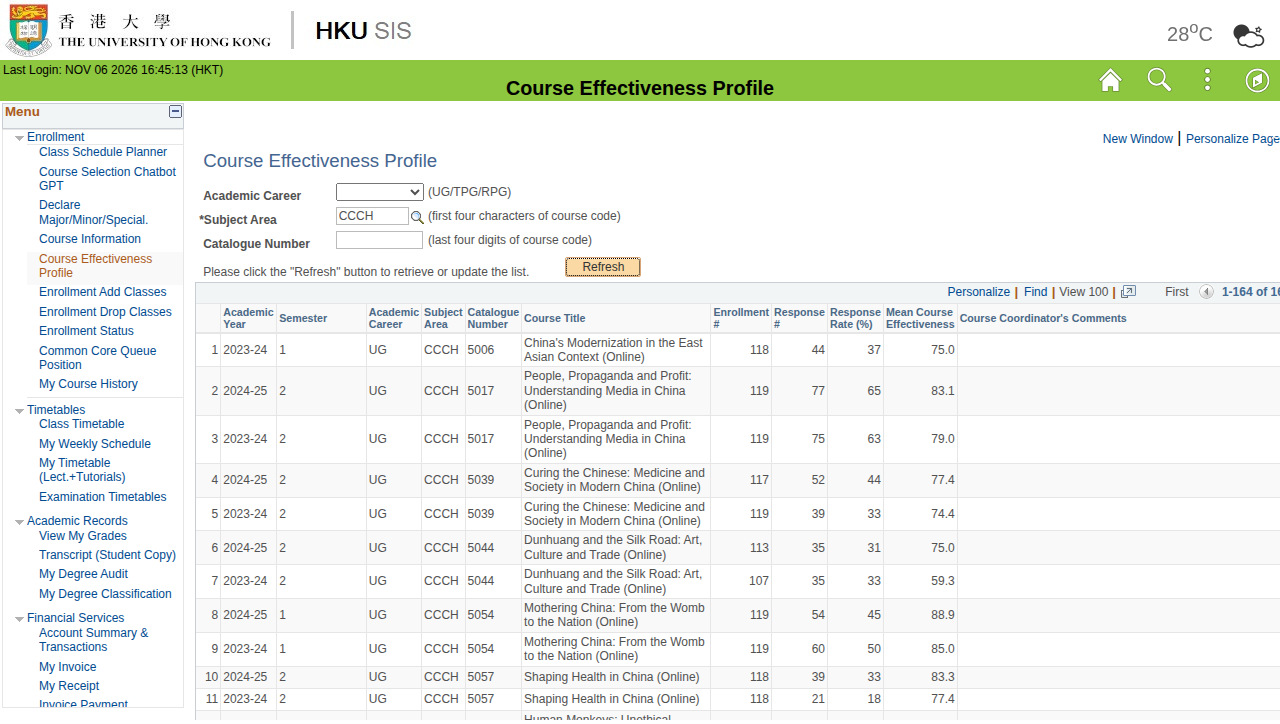

CCAI


AssertionError: Locator expected to contain text 'CCAI'
Actual value:   
Call log:
  - Expect "to_contain_text" locator("#Z_SETL_FDBK_VW_SUBJECT\\$109\\$\\$0") with timeout 5000ms
  - waiting for locator("#Z_SETL_FDBK_VW_SUBJECT\\$109\\$\\$0")
    7 × locator resolved to <span class="PSEDITBOX_DISPONLY" id="Z_SETL_FDBK_VW_SUBJECT$109$$0">CCCH</span>
      - unexpected value "CCCH"
    7 × locator resolved to <span class="PSEDITBOX_DISPONLY" id="Z_SETL_FDBK_VW_SUBJECT$109$$0"> </span>
      - unexpected value " "


In [42]:
# scrape course data

from bs4 import BeautifulSoup
from playwright.async_api import expect

courses = []
effective_info = {}

async def scan_inquiry(inquiry):
	print(inquiry)

	frame = page.frame(name="TargetContent")
	await frame.locator("#Z_SETL_SRCH_DR_SUBJECT").fill(inquiry)
	await frame.locator("#Z_SETL_SRCH_DR_REFRESH").click()
	await expect(frame.locator("#Z_SETL_FDBK_VW_SUBJECT\\$109\\$\\$0")).to_contain_text(inquiry)

	img = await page.screenshot(full_page=True)
	display(Image(img))
	
	html = await frame.content()
	soup = BeautifulSoup(html, "html.parser")

	for elem in soup.select(".PSLEVEL1GRID > tbody > tr")[1:]:
		row = elem.select("td > div")

		course_num = row[4].get_text().strip()
		course_code = inquiry + course_num
		
		info = {
			"year": row[0].get_text().strip(),
			"enrollment": row[6].get_text().strip(),
			"responses": row[7].get_text().strip(),
			"mean_course_effective": row[9].get_text().strip(),
		}

		if course_code not in effective_info:
			effective_info[course_code] = []
		effective_info[course_code].append(info)

await page.goto("https://sis-main.hku.hk/psp/sisprod/EMPLOYEE/PSFT_CS/c/Z_SS_MENU.Z_SETL_FDBK_ENQ.GBL?FolderPath=PORTAL_ROOT_OBJECT.Z_SIS_MENU.Z_ENROLLMENT.Z_SETL_FDBK_ENQ_GBL_1&IsFolder=false&IgnoreParamTempl=FolderPath%2cIsFolder")

for inquiry in ["CCST", "CCHU", "CCGL", "CCCH", "CCAI"]:
	await scan_inquiry(inquiry)

# for course in courses:
# 	await scan_course(course)

In [43]:
# write to output file

import json

output_path = "sis-info.json"

print(json.dumps(effective_info, indent=4))

with open(output_path, "w") as file:
	json.dump(effective_info, file, indent=4)

{
    "CCST5002": [
        {
            "year": "2023-24",
            "enrollment": "68",
            "responses": "13",
            "mean_course_effective": "78.8"
        }
    ],
    "CCST5035": [
        {
            "year": "2024-25",
            "enrollment": "119",
            "responses": "58",
            "mean_course_effective": "81.5"
        }
    ],
    "CCST5037": [
        {
            "year": "2024-25",
            "enrollment": "119",
            "responses": "77",
            "mean_course_effective": "83.1"
        },
        {
            "year": "2023-24",
            "enrollment": "82",
            "responses": "49",
            "mean_course_effective": "81.1"
        }
    ],
    "CCST5068": [
        {
            "year": "2024-25",
            "enrollment": "118",
            "responses": "58",
            "mean_course_effective": "91.4"
        }
    ],
    "CCST5078": [
        {
            "year": "2023-24",
            "enrollment": "120",
            

In [ ]:
await browser.close()
await playwright.close()